In [2]:
import os
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier

In [3]:
print("📁 Loading and cleaning datasets...")

phish_df = pd.read_csv('D:\\Arvin\\extension\\dataset\\CEAS_08.csv')
phish_df = phish_df[['body', 'label']].rename(columns={'body': 'text'})
phish_df['label'] = phish_df['label'].map({0: 'Phishing', 1: 'Safe'})
print(f"  -> Phishing Data Ready: {len(phish_df)} rows")

spam_df = pd.read_csv('D:\\Arvin\\extension\\dataset\\spam.csv', encoding='latin-1')
spam_df = spam_df[['v1', 'v2']].rename(columns={'v1': 'label', 'v2': 'text'})
spam_df['label'] = spam_df['label'].map({'ham': 'Safe', 'spam': 'Spam'})
print(f"  -> Spam Data Ready: {len(spam_df)} rows")

violent_df = pd.read_csv('D:\\Arvin\\extension\\dataset\\labeled_data.csv')
violent_df = violent_df[violent_df['class'].isin([0, 1])]
violent_df = violent_df[['tweet', 'class']].rename(columns={'tweet': 'text'})
violent_df['label'] = 'Violent' 
print(f"  -> Violent/Hate Data Ready: {len(violent_df)} rows")

📁 Loading and cleaning datasets...
  -> Phishing Data Ready: 39154 rows
  -> Spam Data Ready: 5572 rows
  -> Violent/Hate Data Ready: 20620 rows


🔀 Merging all datasets...

📊 Total Rows in Unified Dataset: 65346

📈 Dataset Distribution Per Class:
label
Safe        26667
Violent     20620
Phishing    17312
Spam          747
Name: count, dtype: int64


C:\Users\HOME\AppData\Local\Temp\ipykernel_19204\2460652475.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=final_df, palette='viridis')


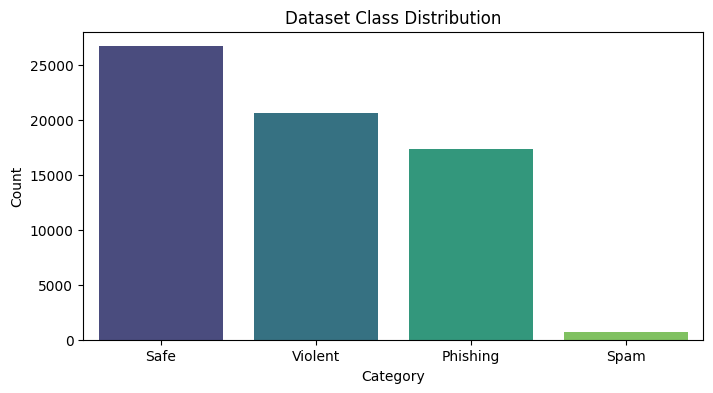

In [4]:
print("🔀 Merging all datasets...")
final_df = pd.concat([phish_df, spam_df, violent_df], ignore_index=True)

final_df = final_df.dropna(subset=['text', 'label'])
final_df = final_df.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\n📊 Total Rows in Unified Dataset: {len(final_df)}")
print("\n📈 Dataset Distribution Per Class:")
print(final_df['label'].value_counts())

plt.figure(figsize=(8, 4))
sns.countplot(x='label', data=final_df, palette='viridis')
plt.title('Dataset Class Distribution')
plt.xlabel('Category')
plt.ylabel('Count')
plt.show()

🏋️ Training 4 Different ML Models for Comparative Analysis...

🔄 Training Multinomial Naive Bayes (Please wait)...
✅ Multinomial Naive Bayes Training Complete! Accuracy: 93.90%

🔄 Training Logistic Regression (Please wait)...
✅ Logistic Regression Training Complete! Accuracy: 98.32%

🔄 Training Linear SVM (SGD) (Please wait)...
✅ Linear SVM (SGD) Training Complete! Accuracy: 98.41%

🔄 Training Random Forest (Please wait)...
✅ Random Forest Training Complete! Accuracy: 88.38%

📊 Comparative Matrix Summary:
 - Multinomial Naive Bayes: 93.90%
 - Logistic Regression: 98.32%
 - Linear SVM (SGD): 98.41%
 - Random Forest: 88.38%



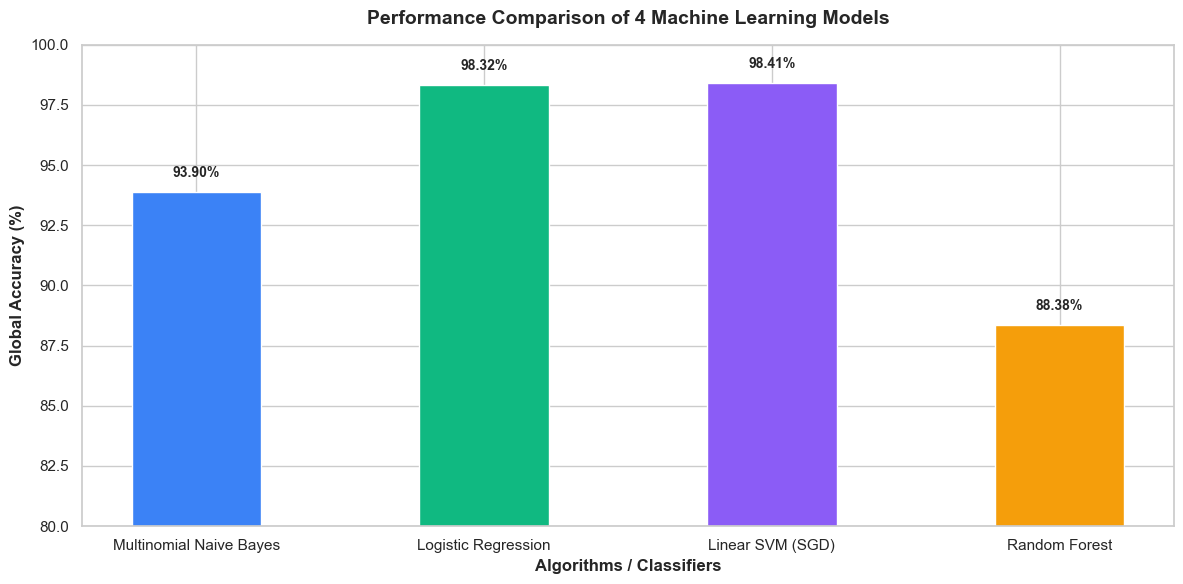

In [5]:
X = final_df['text']
y = final_df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

models = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=0.01),
    'Logistic Regression': LogisticRegression(max_iter=1000, C=1.0, random_state=42),
    'Linear SVM (SGD)': SGDClassifier(loss='hinge', penalty='l2', alpha=1e-4, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
}

model_accuracies = {}
model_pipelines = {}

print("="*60)
print("🏋️ Training 4 Different ML Models for Comparative Analysis...")
print("="*60 + "\n")

for model_name, model_obj in models.items():
    print(f"🔄 Training {model_name} (Please wait)...")
    
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', max_features=30000, ngram_range=(1, 2))),
        ('clf', model_obj)
    ])
    
    pipeline.fit(X_train, y_train)
    
    y_pred = pipeline.predict(X_test)
    acc = accuracy_score(y_test, y_pred) * 100
    
    model_accuracies[model_name] = acc
    model_pipelines[model_name] = pipeline
    
    print(f"✅ {model_name} Training Complete! Accuracy: {acc:.2f}%\n")

print("="*60)
print("📊 Comparative Matrix Summary:")
for name, score in model_accuracies.items():
    print(f" - {name}: {score:.2f}%")
print("="*60 + "\n")

plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

colors = ['#3b82f6', '#10b981', '#8b5cf6', '#f59e0b']
bars = plt.bar(model_accuracies.keys(), model_accuracies.values(), color=colors, width=0.45)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.title('Performance Comparison of 4 Machine Learning Models', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Algorithms / Classifiers', fontsize=12, fontweight='bold')
plt.ylabel('Global Accuracy (%)', fontsize=12, fontweight='bold')
plt.ylim(80, 100)
plt.tight_layout()
plt.show()

In [8]:
best_model_name = max(model_accuracies, key=model_accuracies.get)
best_pipeline = model_pipelines[best_model_name]

print(f"🏆 The Best/Suitable Model for this dataset is: '{best_model_name}'")
print(f"🎯 Peak Accuracy Achieved: {model_accuracies[best_model_name]:.2f}%")

with open('model.pkl', 'wb') as model_file:
    pickle.dump(best_pipeline, model_file)

print(f"💾 [SUCCESS] '{best_model_name}' pipeline successfully saved as 'model.pkl'!")

🏆 The Best/Suitable Model for this dataset is: 'Linear SVM (SGD)'
🎯 Peak Accuracy Achieved: 98.41%
💾 [SUCCESS] 'Linear SVM (SGD)' pipeline successfully saved as 'model.pkl'!
